# Tagalog trends: lifecycles and forecasting

The third notebook. `google_trends.ipynb` found each term's peak and compared the weeks around it;
`google_trends_ml.ipynb` compared per-term models one step ahead. This one works from the `tagatrend`
package and the stitched data in `data/processed/`, and asks two questions:

1. **Do Filipino viral terms share a lifecycle?** Align every term on its peak day, measure the rise
   and decay, and fit decay curves.
2. **Can a model forecast a term it has never seen?** Global models trained on every other term, scored
   on the held-out one, 28 days and 12 weeks ahead, with intervals.

Run `scripts/build_dataset.py` and `scripts/train_models.py` first. The backtest is stored in
`data/models/`; set `RUN_BACKTEST = True` below to recompute it here on the GPU.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.optimize import curve_fit

sys.path.insert(0, str(Path.cwd()))
from tagatrend import analysis
from tagatrend.catalog import TRENDS
from tagatrend.config import END_DATE, MODEL_DIR
from tagatrend.series import read_series

RUN_BACKTEST = False
BLUE, AMBER, RED, GREY = "#0038a8", "#a86f0c", "#ce1126", "#9a9c9e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.grid.axis": "y"})

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. The global models train on the GPU only.")
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| CUDA", torch.version.cuda)

GPU: NVIDIA GeForce RTX 5090 Laptop GPU | torch 2.14.1+cu130 | CUDA 13.0


## 1. What was collected

Each term has a monthly backbone (2004 onwards), and where Google allowed it a stitched weekly series
and a daily series around the peak (`tagatrend/series.py`). Rows ≥ 10% of the peak are where a
forecaster has something to learn.

In [2]:
series = {e["slug"]: {f: read_series(e["slug"], f) for f in ("monthly", "weekly", "daily")} for e in TRENDS}
names = {e["slug"]: e["query"] for e in TRENDS}
rows = []
for slug, by_freq in series.items():
    if by_freq["monthly"] is None:
        continue
    for freq, s in by_freq.items():
        if s is None:
            continue
        valid = s.dropna()
        rows.append({"Term": names[slug], "Series": freq, "Rows": len(s), "From": f"{s.index.min():%Y-%m-%d}",
                     "To": f"{s.index.max():%Y-%m-%d}", "Missing": int(s.isna().sum()),
                     "Rows >= 10% of peak": int((valid >= 0.1 * valid.max()).sum())})
coverage = pd.DataFrame(rows)
display(coverage.pivot_table(index="Term", columns="Series", values="Rows", aggfunc="first").fillna(0).astype(int))

Series,daily,monthly,weekly
Term,,,
AlDub,260,273,313
Budol,260,273,314
Charot,0,273,314
Dasurv,260,273,0
Forda,260,273,314
Fox Silica,149,273,0
Jejemon,260,273,314
Lodi,260,273,314
Marites,260,273,314


## 2. Lifecycle measures

Rise is days from 10% of the peak to the peak; half-life is days from the peak down to 50%; fade
is down to 10% (centred 7-day mean on the daily series). Definitions are in `docs/PIPELINE.md`.

In [3]:
life = []
for slug, by_freq in series.items():
    if by_freq["monthly"] is None:
        continue
    summary = analysis.summarize(by_freq, END_DATE)
    c = summary["lifecycle"] or {}
    life.append({"Term": names[slug], "Peak": c.get("peak_date"), "Rise (d)": c.get("rise_days"),
                 "Half-life (d)": c.get("half_life_days"), "Fade (d)": c.get("fade_days"),
                 "Left after 4 weeks (%)": c.get("retention_4w_pct"), "Shape": summary["shape"],
                 "Now": summary["phase"]["phase"]})
life = pd.DataFrame(life).sort_values("Half-life (d)")
display(life.round(1))
print("Median rise:", life["Rise (d)"].median(), "days | median half-life:", life["Half-life (d)"].median(), "days")

,Term,Peak,Rise (d),Half-life (d),Fade (d),Left after 4 weeks (%),Shape,Now
3,Fox Silica,2026-07-29,6,3,6.0,0.0,Flash,Dormant
6,Pak Ganern,2016-08-24,7,3,10.0,2.4,Flash,Dormant
11,Budol,2022-08-01,33,4,17.0,9.7,Flash,Fading
4,Jejemon,2010-04-30,16,5,118.0,23.8,Flash,Dormant
2,Never Grow Old,2026-09-11,7,6,15.0,0.7,Flash,Dormant
1,Pabebe Girls,2015-07-12,16,6,25.0,7.8,Flash,Dormant
9,Werpa,2005-04-30,1,7,7.0,0.0,Flash,Dormant
10,Naol,2020-06-22,1,7,7.0,0.0,Flash,Dormant
13,Dasurv,2011-05-24,1,7,7.0,0.0,Flash,Dormant
16,What Haffen Vella,2025-05-28,1,7,7.0,0.0,Flash,Dormant


Median rise: 15.5 days | median half-life: 7.0 days


### Every daily lifecycle on one clock

Each daily series is shifted so its peak is day 0 and divided by its peak 7-day mean. The thick line is
the median across terms: the typical shape of a Filipino viral search spike.

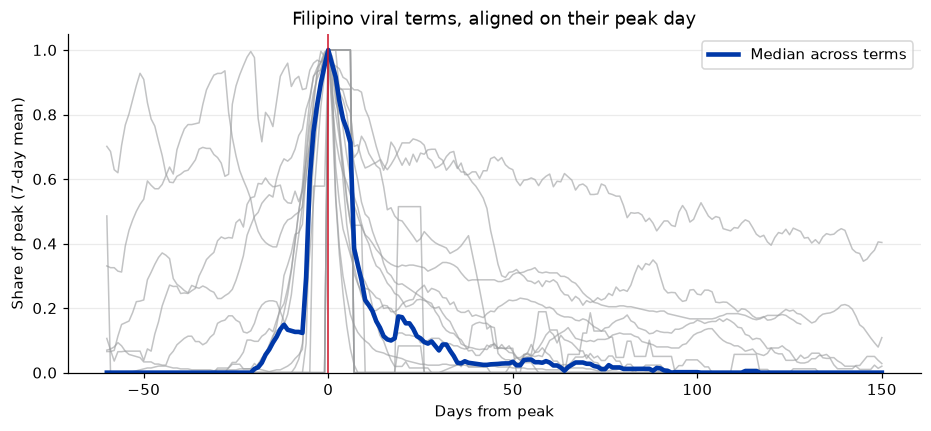

In [4]:
aligned = {}
for slug, by_freq in series.items():
    s = by_freq["daily"]
    if s is None or s.max() <= 0:
        continue
    smooth = s.interpolate(limit_area="inside").rolling(7, center=True, min_periods=1).mean()
    peak = smooth.idxmax()
    rel = pd.Series(smooth.to_numpy() / smooth.max(), index=(s.index - peak).days)
    aligned[names[slug]] = rel.loc[-60:150]
frame = pd.DataFrame(aligned)
fig, ax = plt.subplots(figsize=(10, 4))
for name in frame:
    ax.plot(frame.index, frame[name], color=GREY, linewidth=1, alpha=0.6)
ax.plot(frame.index, frame.median(axis=1), color=BLUE, linewidth=3, label="Median across terms")
ax.axvline(0, color=RED, linewidth=1)
ax.set(xlabel="Days from peak", ylabel="Share of peak (7-day mean)", ylim=(0, 1.05),
       title="Filipino viral terms, aligned on their peak day")
ax.legend(loc="upper right")
plt.show()

### Exponential or power-law decay?

After the peak, attention usually decays either exponentially (a fixed half-life) or as a power law
(fast at first, then a long tail). Fit both to the 120 days after each peak and compare the error.

In [5]:
def expo(t, a, k):
    return a * np.exp(-k * t)

def power(t, a, b):
    return a * (1 + t) ** (-b)

fits = []
for name, rel in aligned.items():
    tail = rel.loc[0:120].dropna()
    t, y = tail.index.to_numpy(float), tail.to_numpy()
    if len(t) < 20:
        continue
    row = {"Term": name, "Days fitted": len(t)}
    for label, f, p0 in (("Exponential", expo, (1, 0.05)), ("Power law", power, (1, 0.5))):
        try:
            params, _ = curve_fit(f, t, y, p0=p0, maxfev=20000)
            row[f"{label} RMSE"] = float(np.sqrt(np.mean((f(t, *params) - y) ** 2)))
            row[f"{label} param"] = float(params[1])
        except RuntimeError:
            row[f"{label} RMSE"] = np.nan
    row["Better fit"] = "Power law" if row["Power law RMSE"] < row["Exponential RMSE"] else "Exponential"
    fits.append(row)
fits = pd.DataFrame(fits)
display(fits.round(3))
print(fits["Better fit"].value_counts().to_string())

,Term,Days fitted,Exponential RMSE,Exponential param,Power law RMSE,Power law param,Better fit
0,Sana All,121,0.072,0.016,0.129,0.337,Exponential
1,Pabebe Girls,121,0.023,0.103,0.072,0.744,Exponential
2,Never Grow Old,48,0.030,0.146,0.121,0.745,Exponential
3,Fox Silica,89,0.034,0.370,0.061,1.068,Exponential
4,Jejemon,121,0.108,0.016,0.055,0.467,Power law
5,AlDub,121,0.070,0.012,0.032,0.352,Power law
6,Pak Ganern,121,0.020,0.269,0.032,0.944,Exponential
7,Lodi,121,0.036,0.060,0.100,0.609,Exponential
8,Petmalu,121,0.032,0.068,0.088,0.645,Exponential
9,Werpa,121,0.103,0.181,0.151,0.852,Exponential


Better fit
Exponential    13
Power law       4


In [6]:
expo_terms = fits.loc[fits["Better fit"] == "Exponential", "Term"].tolist()
power_terms = fits.loc[fits["Better fit"] == "Power law", "Term"].tolist()
print(f"Exponential (a fixed half-life) fits {len(expo_terms)} of {len(fits)}: {', '.join(expo_terms) or 'none'}.")
print(f"Power law (fast drop, then a long tail) fits {len(power_terms)} of {len(fits)}: {', '.join(power_terms) or 'none'}.")

Exponential (a fixed half-life) fits 13 of 17: Sana All, Pabebe Girls, Never Grow Old, Fox Silica, Pak Ganern, Lodi, Petmalu, Werpa, Naol, Dasurv, Forda, What Haffen Vella, Trentahin.
Power law (fast drop, then a long tail) fits 4 of 17: Jejemon, AlDub, Budol, Marites.


## 3. Forecasting a term the models have never seen

The task: from a forecast date, predict the next 28 days (daily) or 12 weeks (weekly), with a median
and an 80% band. Everything is scaled by the **peak so far**, because the stitched series' own 0-100
scale leaks whether the peak has happened. The learned models predict the log-change from the last
value, so "no change" is exactly the naive forecast and the model learns only departures from it.

| Model | What it is |
|---|---|
| Naive | Repeat the last value (the notebooks' baseline) |
| XGBoost | Quantile gradient boosting with the horizon as a feature, GPU |
| MLP | Quantile MLP, median of 5 seeds, GPU |
| TimesFM | Google's pretrained 200M forecaster, zero-shot, GPU |
| Ensemble | Weighted by each model's validation error on the *training* terms |

**Grouped leave-one-term-out:** the models forecasting a term were trained without it (and without
its same-era siblings: Lodi/Petmalu/Werpa, Sana All/Naol).

In [7]:
if RUN_BACKTEST:
    from tagatrend.evaluate import backtest, score, summary
    reports = {}
    for freq in ("daily", "weekly"):
        data, predictions, folds = backtest(freq)
        scores = score(data, predictions, freq)
        reports[freq] = {"overall": summary(scores), "by_phase": summary(scores, ["phase"]),
                         "by_horizon": summary(scores, ["h"]), "by_trend": summary(scores, ["trend"])}
else:
    reports = {}
    for freq in ("daily", "weekly"):
        path = MODEL_DIR / freq / "metrics.json"
        if path.exists():
            m = json.loads(path.read_text(encoding="utf-8"))
            reports[freq] = {k: pd.DataFrame(m[k]) for k in ("overall", "by_phase", "by_horizon", "by_trend")}
            reports[freq]["folds"] = m.get("folds", [])

ORDER = ["Ensemble", "TimesFM", "XGBoost", "MLP", "Drift", "Mean of last 7", "Naive"]
for freq, r in reports.items():
    table = r["overall"].set_index("model").reindex(ORDER).dropna(how="all")
    print(f"{freq}: mean absolute error (index points) and skill vs naive, all horizons")
    display(table[["mae_index", "skill_pct", "coverage_80", "n"]].round(2))

daily: mean absolute error (index points) and skill vs naive, all horizons


,mae_index,skill_pct,coverage_80,n
model,,,,
Ensemble,8.12,31.80,0.78,52740
TimesFM,8.94,24.94,0.79,52740
XGBoost,7.99,32.92,0.68,52740
MLP,9.20,22.76,0.80,52740
Drift,17.80,-49.42,0.14,52740
Mean of last 7,12.58,-5.61,0.12,52740
Naive,11.91,0.00,0.20,52740


weekly: mean absolute error (index points) and skill vs naive, all horizons


,mae_index,skill_pct,coverage_80,n
model,,,,
Ensemble,6.25,16.03,0.75,22308
TimesFM,6.20,16.66,0.78,22308
XGBoost,7.07,5.00,0.75,22308
MLP,6.42,13.68,0.79,22308
Drift,8.78,-17.98,0.15,22308
Mean of last 7,7.70,-3.43,0.14,22308
Naive,7.44,0.00,0.28,22308


### Skill by lifecycle phase

*Rise* is before the term's eventual peak, *Peak* the two weeks after it, *Decay* the rest. The labels
use the future and exist only for scoring.

In [8]:
for freq, r in reports.items():
    phase = r["by_phase"].pivot(index="model", columns="phase", values="skill_pct")
    display(phase.reindex([m for m in ORDER if m in phase.index])[["Rise", "Peak", "Decay"]].round(1)
            .style.set_caption(f"{freq}: skill vs naive (%) by phase"))

phase,Rise,Peak,Decay
model,,,
Ensemble,-0.100000,57.600000,40.400000
TimesFM,-5.500000,65.900000,26.000000
XGBoost,-0.600000,45.400000,48.400000
MLP,-8.700000,40.200000,34.700000
Drift,-44.700000,-142.100000,-11.600000
Mean of last 7,3.200000,-5.400000,-11.200000
Naive,0.000000,0.000000,0.000000


phase,Rise,Peak,Decay
model,,,
Ensemble,4.900000,46.800000,17.400000
TimesFM,1.800000,56.000000,19.000000
XGBoost,0.800000,28.600000,2.800000
MLP,2.200000,39.800000,16.500000
Drift,-8.800000,18.000000,-33.400000
Mean of last 7,-1.800000,45.800000,-16.100000
Naive,0.000000,0.000000,0.000000


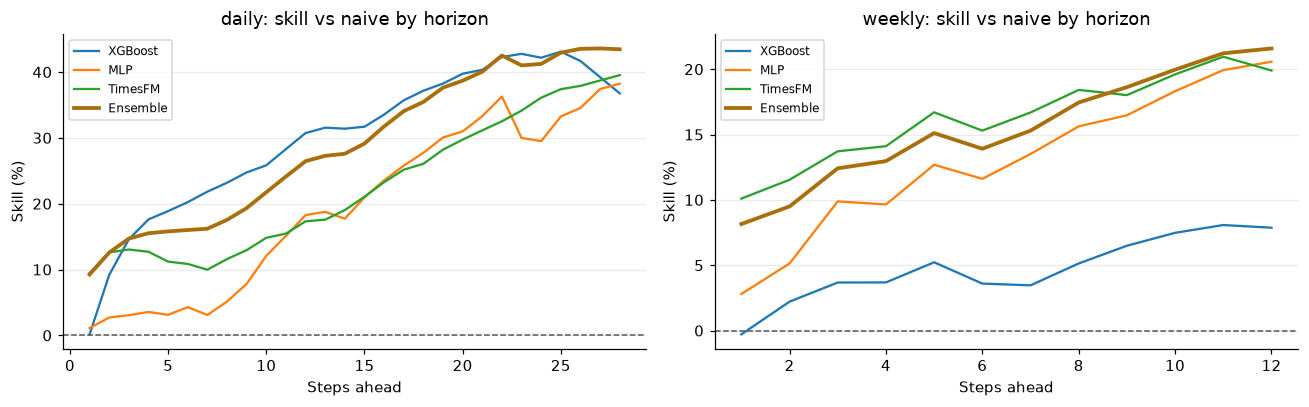

In [9]:
fig, axes = plt.subplots(1, len(reports), figsize=(12, 3.8), squeeze=False)
for ax, (freq, r) in zip(axes[0], reports.items()):
    h = r["by_horizon"]
    for model in ["XGBoost", "MLP", "TimesFM", "Ensemble"]:
        part = h[h["model"] == model].sort_values("h")
        if len(part):
            ax.plot(part["h"], part["skill_pct"], label=model, linewidth=2.5 if model == "Ensemble" else 1.5,
                    color=AMBER if model == "Ensemble" else None)
    ax.axhline(0, color="#555", linestyle="--", linewidth=1)
    ax.set(title=f"{freq}: skill vs naive by horizon", xlabel="Steps ahead", ylabel="Skill (%)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
for freq, r in reports.items():
    t = r["by_trend"]
    wide = t.pivot(index="trend", columns="model", values="skill_pct")
    wide.index = [names.get(i, i) for i in wide.index]
    cols = [m for m in ORDER if m in wide.columns and m != "Naive"]
    display(wide[cols].sort_values("Ensemble", ascending=False).round(1)
            .style.set_caption(f"{freq}: skill vs naive (%) for each held-out term"))
    if r.get("folds"):
        weights = pd.DataFrame([{"Held out": ", ".join(names.get(s, s) for s in f["held_out"]), **f["weights"]}
                                for f in r["folds"]]).set_index("Held out")
        display(weights.round(2).style.set_caption(f"{freq}: ensemble weights chosen on the training terms"))

model,Ensemble,TimesFM,XGBoost,MLP,Drift,Mean of last 7
Werpa,76.000000,65.900000,93.500000,69.500000,-31.500000,-18.800000
What Haffen Vella,75.600000,67.600000,93.600000,64.600000,-32.600000,-19.500000
Dasurv,73.100000,57.700000,93.800000,68.200000,-32.600000,-19.500000
Naol,69.200000,38.100000,100.000000,68.400000,-33.000000,-21.500000
Petmalu,48.000000,27.500000,27.500000,45.100000,-74.500000,-14.900000
Pabebe Girls,32.500000,23.300000,33.000000,29.900000,-66.900000,-5.200000
Lodi,32.400000,18.700000,18.300000,31.600000,-65.300000,-10.200000
Budol,27.600000,32.000000,30.200000,9.100000,-47.300000,3.600000
Jejemon,27.400000,11.500000,21.700000,9.300000,-100.500000,-2.500000
Pak Ganern,25.800000,58.700000,50.200000,-37.000000,-65.000000,-6.700000


,XGBoost,MLP,TimesFM
Held out,,,
AlDub,0.330000,0.330000,0.340000
Budol,0.340000,0.290000,0.370000
Dasurv,0.340000,0.290000,0.370000
Forda,0.300000,0.320000,0.380000
Fox Silica,0.320000,0.320000,0.360000
Jejemon,0.310000,0.320000,0.360000
"Lodi, Petmalu, Werpa",0.330000,0.280000,0.390000
Marites,0.360000,0.300000,0.340000
"Naol, Sana All",0.350000,0.300000,0.340000


model,Ensemble,TimesFM,XGBoost,MLP,Drift,Mean of last 7
Petmalu,46.300000,59.500000,37.100000,34.500000,-12.900000,-14.500000
Pak Ganern,43.500000,56.200000,35.600000,36.300000,36.500000,-4.500000
Pabebe Girls,39.100000,66.800000,8.000000,28.200000,-10.400000,-11.300000
Lodi,31.400000,31.600000,27.300000,33.000000,-22.700000,-11.100000
AlDub,29.300000,11.200000,20.600000,22.200000,-49.100000,-34.700000
Budol,24.300000,33.000000,12.300000,16.600000,-6.600000,6.600000
Jejemon,23.600000,17.700000,20.000000,26.900000,-10.900000,-7.500000
What Haffen Vella,17.800000,22.300000,10.700000,17.200000,-4.600000,-14.500000
Sana All,14.800000,15.100000,2.400000,11.800000,-36.500000,-13.200000
Forda,14.100000,5.100000,15.900000,17.500000,-34.000000,-21.700000


,XGBoost,MLP,TimesFM
Held out,,,
AlDub,0.320000,0.320000,0.370000
Budol,0.310000,0.320000,0.380000
Charot,0.310000,0.330000,0.360000
Forda,0.310000,0.320000,0.370000
Jejemon,0.310000,0.330000,0.360000
"Lodi, Petmalu",0.320000,0.310000,0.370000
Marites,0.330000,0.330000,0.350000
"Naol, Sana All",0.310000,0.330000,0.370000
Pabebe Girls,0.310000,0.320000,0.370000


### Replays: what the models said before it happened

Out-of-fold forecasts stored by `train_models.py` (every 7th day / 2nd week). Each panel picks the
origin a few periods before the peak and one after it.

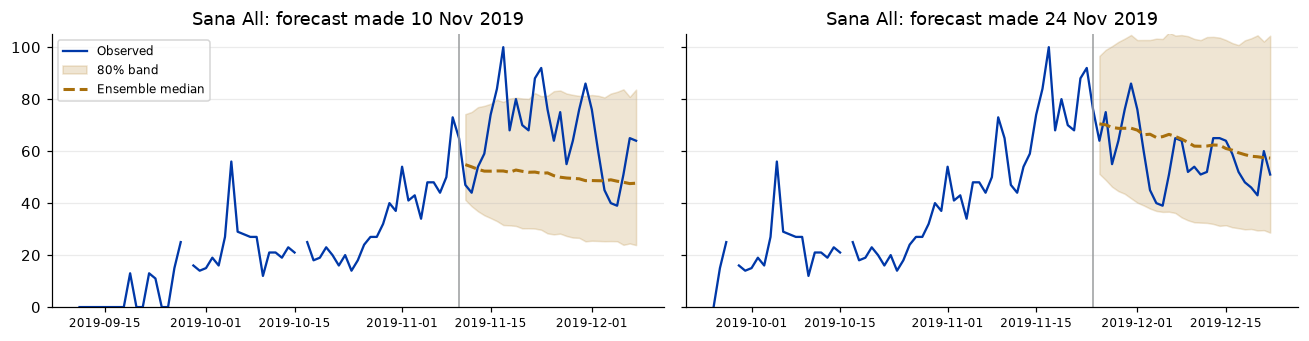

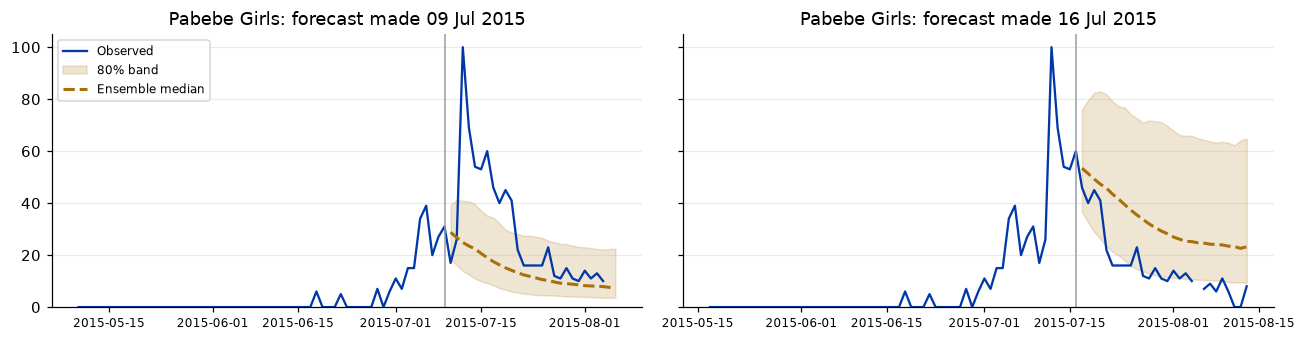

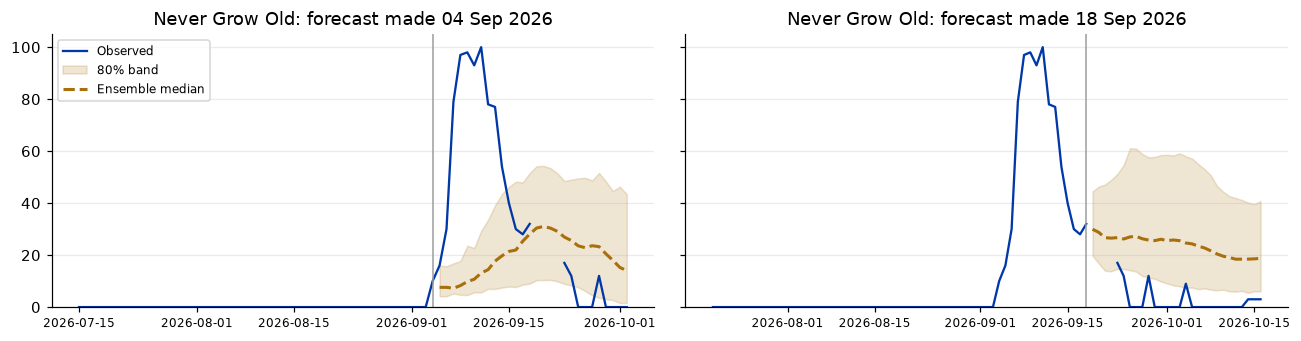

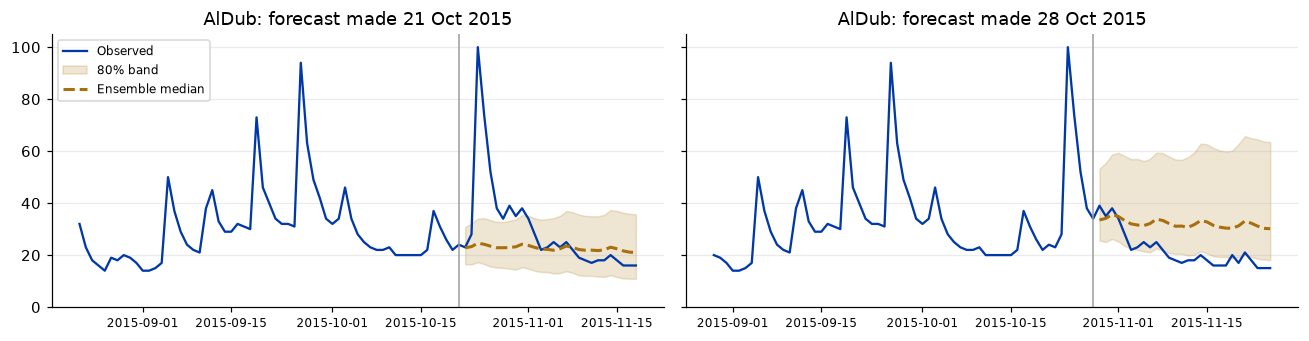

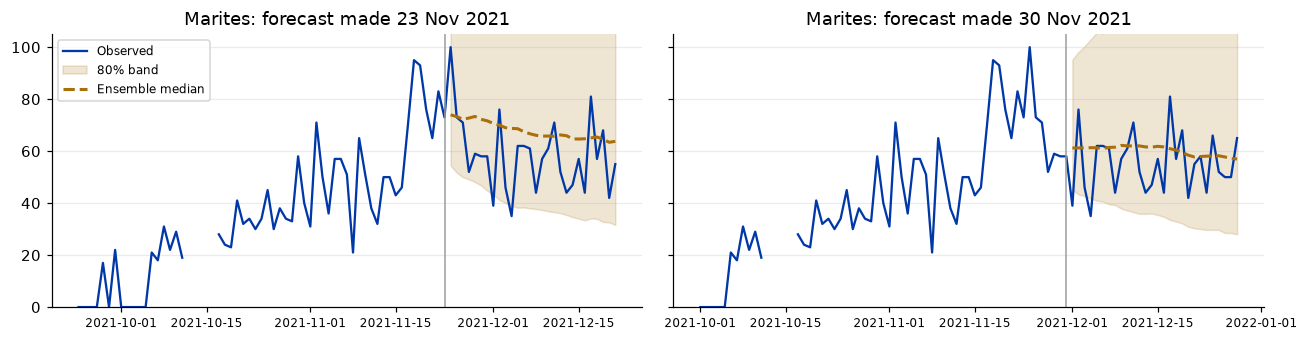

In [11]:
def replay_plot(slug, freq, model="Ensemble"):
    path = MODEL_DIR / freq / "backtest" / f"{slug}.json"
    s = series[slug][freq]
    if not path.exists() or s is None:
        return
    origins = json.loads(path.read_text(encoding="utf-8"))["origins"]
    peak = s.idxmax()
    dates = [pd.Timestamp(o["date"]) for o in origins]
    before = max([i for i, d in enumerate(dates) if d < peak] or [0])
    after = min([i for i, d in enumerate(dates) if d > peak] or [len(dates) - 1])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
    step = pd.Timedelta(days=1 if freq == "daily" else 7)
    for ax, i in zip(axes, (before, after)):
        o = origins[i]
        origin = pd.Timestamp(o["date"])
        q10, q50, q90 = (np.array(v) for v in o["models"][model])
        future = [origin + step * (h + 1) for h in range(len(q50))]
        window = s.loc[origin - step * 60:future[-1]]
        ax.plot(window.index, window, color=BLUE, linewidth=1.5, label="Observed")
        ax.fill_between(future, q10, q90, color=AMBER, alpha=0.18, label="80% band")
        ax.plot(future, q50, color=AMBER, linestyle="--", linewidth=2, label=f"{model} median")
        ax.axvline(origin, color=GREY, linewidth=1)
        ax.set(title=f"{names[slug]}: forecast made {origin:%d %b %Y}", ylim=(0, 105))
        ax.tick_params(axis="x", labelrotation=0, labelsize=8)
    axes[0].legend(fontsize=8, loc="upper left")
    plt.tight_layout()
    plt.show()

for slug in ("sana_all", "pabebe_girls", "never_grow_old", "aldub", "marites"):
    for freq in ("daily",):
        replay_plot(slug, freq)

## 4. What drives the XGBoost forecast

TreeSHAP attributions from XGBoost itself (`pred_contribs=True`), for the production weekly model and
its **median** output. The explained output is the predicted log-change from the last value at each
horizon; attributions plus the bias equal the model's raw output, which is checked below. Rows are the
validation part of every term (the last 20% of origins).

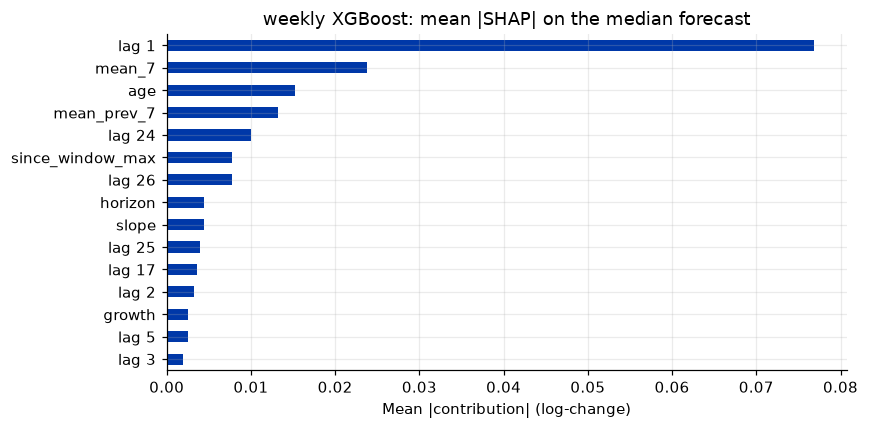

Additivity check passed on 7716 rows.


In [12]:
import xgboost as xgb
from tagatrend.evaluate import load_origins, pooled_split
from tagatrend.features import EXTRA_FEATURES, SETTINGS
from tagatrend.models.global_models import GlobalXGB

freq = "weekly" if (MODEL_DIR / "weekly" / "xgb.ubj").exists() else "daily"
cfg = SETTINGS[freq]
model = GlobalXGB.load(MODEL_DIR / freq / "xgb.ubj", cfg["horizon"])
model.booster.set_param({"device": "cuda"})
data = load_origins(freq)
_, _, xv, yv = pooled_split(data, list(data))
dm = model._matrix(xv)
contribs = model.booster.predict(dm, pred_contribs=True, iteration_range=(0, model.booster.best_iteration + 1))
margin = model.booster.predict(dm, output_margin=True, iteration_range=(0, model.booster.best_iteration + 1))
median = 1  # quantile index of 0.5
explained = contribs[:, median, :] if contribs.ndim == 3 else contribs
assert np.allclose(explained.sum(axis=1), margin.reshape(len(margin), -1)[:, median], atol=1e-3), "SHAP additivity failed"
features = [f"lag {i}" for i in range(cfg["lookback"], 0, -1)] + EXTRA_FEATURES + ["horizon"]
importance = pd.Series(np.abs(explained[:, :-1]).mean(axis=0), index=features).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
importance.head(15)[::-1].plot.barh(ax=ax, color=BLUE)
ax.set(title=f"{freq} XGBoost: mean |SHAP| on the median forecast", xlabel="Mean |contribution| (log-change)")
plt.tight_layout()
plt.show()
print("Additivity check passed on", len(explained), "rows.")

## 5. Reading the results

- **Lifecycles are shared, but not identical.** The median term rises in about two weeks and loses half
  its interest within a week of the peak (section 2). Flash spikes decay like a fixed half-life; the
  terms with long tails are the ones a power law describes better (section 2's fit table).
- **The explosion is not forecastable from search data alone.** Skill in the rise phase is near or
  below zero for every model: nothing in a flat line says a spike is coming.
- **Once a term has peaked, the decay is.** Peak and decay are where the global models and TimesFM
  beat the naive forecast, because every other term taught them how a decay goes.
- **Differences under about 6 index points are inside Google's own sampling noise** between pull days.

The next phase adds a signal that moves *before* the search spike: Reddit posts asking what a term
means, collected with uyam's Shreddit pipeline (see `docs/PIPELINE.md`, section 6).